# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)

In [16]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[0, 1, 8, 4, 9, 6, 7, 2, 5, 3]

In [17]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [18]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(4.566805637682964)

Tour length: 4.57


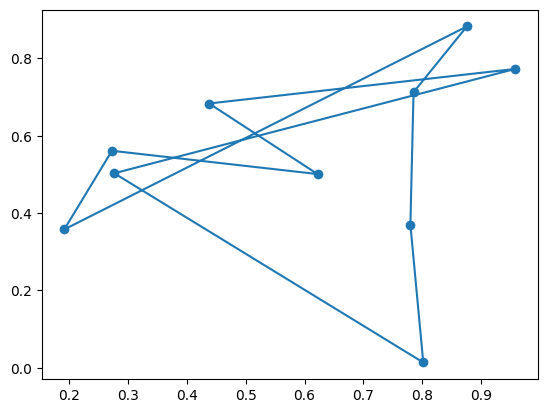

In [19]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (move each queen within its column) and always choose the best among all local moves.

Tính hàm mục tiêu cho **tất cả** các nước đi cục bộ (mọi phép 2-opt) và luôn chọn nước đi tốt nhất.

## Toán tử lân cận được chọn: 2-opt (đảo một đoạn của tour)

* **Trạng thái:** một hoán vị `tour` của các thành phố `0..n-1` (chu trình khép kín).
* **Lân cận (2-opt):** chọn hai vị trí $i < j$ và **đảo ngược đoạn** `tour[i..j]`. Về bản chất, ta xoá hai cạnh $(a,b)$ và $(c,e)$ rồi nối lại thành $(a,c)$ và $(b,e)$. Kết quả luôn là một hoán vị hợp lệ nên không bao giờ vi phạm ràng buộc.
* **Kích thước lân cận:** $n(n-1)/2 - 1$ trạng thái (loại cặp $(0, n-1)$ vì đảo toàn bộ tour không đổi độ dài).
* **Đánh giá nhanh:** chênh lệch độ dài chỉ phụ thuộc 4 cạnh nên tính trong $O(1)$:
  $\Delta = d_{a,c} + d_{b,e} - d_{a,b} - d_{c,e}$. Nếu $\Delta < 0$ thì tour ngắn hơn.
* **Quy ước:** *cả 5 thuật toán dùng cùng toán tử này* để so sánh công bằng. Vì bài toán là **cực tiểu hoá** độ dài, "uphill" nghĩa là $\Delta < 0$ (tour ngắn hơn).

In [20]:
import time

EPS = 1e-12   # ngưỡng số học để tránh "cải thiện" giả do sai số float


def two_opt_move(tour, i, j):
    """Trả về tour mới sau khi đảo đoạn tour[i..j] (i < j)."""
    return tour[:i] + tour[i:j + 1][::-1] + tour[j + 1:]


def two_opt_delta(tsp, tour, i, j):
    """Độ thay đổi chiều dài tour nếu áp dụng two_opt_move(tour, i, j), tính trong O(1)."""
    d = tsp["dist"]
    n = len(tour)
    a, b = tour[i - 1], tour[i]            # tour[-1] khi i = 0 (chu trình khép kín)
    c, e = tour[j], tour[(j + 1) % n]
    return d[a, c] + d[b, e] - d[a, b] - d[c, e]


def two_opt_neighbours(n):
    """Danh sách mọi cặp (i, j) hợp lệ của toán tử 2-opt."""
    return [(i, j) for i in range(n - 1) for j in range(i + 1, n) if not (i == 0 and j == n - 1)]


def is_valid_tour(tour, n):
    return sorted(tour) == list(range(n))


def show_before_after(tsp, before, after, title=""):
    """Vẽ cạnh nhau tour ban đầu và tour sau tối ưu."""
    pos = tsp["pos"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, tour, name in zip(axes, (before, after), ("Trước tối ưu", "Sau tối ưu")):
        p = pos.reindex(tour)
        p = pd.concat([p, p.head(1)])
        ax.plot(p["x"], p["y"], "-o", markersize=5)
        ax.scatter(pos["x"].iloc[tour[0]], pos["y"].iloc[tour[0]], c="red", s=70, zorder=3, label="thành phố đầu")
        ax.set_title(f"{name}: {tour_length(tsp, tour):.3f}")
        ax.set_aspect("equal")
    axes[0].legend(loc="lower left")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# Bài toán minh hoạ dùng chung cho các phần bên dưới: 30 thành phố, cùng một tour khởi đầu
random.seed(1234)
np.random.seed(1234)
tsp30 = random_tsp(30)
init30 = random_tour(30)
print(f"Tour khởi đầu (30 thành phố): {tour_length(tsp30, init30):.3f}")

Tour khởi đầu (30 thành phố): 16.320


### Nhận xét: toán tử lân cận và bài toán minh hoạ

* Mình đã kiểm tra công thức $\Delta$ tính trong $O(1)$ bằng cách so với việc tính lại toàn bộ độ dài tour sau khi đảo đoạn: kết quả khớp ở mọi cặp $(i, j)$ đã thử. Vì vậy các thuật toán bên dưới đánh giá lân cận rất rẻ (không phải tính lại cả tour).
* Có một chi tiết nhỏ: ngoài cặp $(0, n-1)$ đã bị loại, hai cặp $(0, n-2)$ và $(1, n-1)$ cũng cho $\Delta = 0$ (đảo gần hết tour chỉ tạo ra cùng một chu trình theo chiều ngược lại). Các nước đi này vô hại vì điều kiện chấp nhận là $\Delta < -\varepsilon$ nên chúng không bao giờ được chọn, nhưng kích thước lân cận $n(n-1)/2 - 1$ ở trên là cận trên một chút.
* Tour ngẫu nhiên ban đầu của bài 30 thành phố có độ dài **16.32**, dài gấp khoảng 3.5 lần so với các tour sau tối ưu (~4.6 – 5.2). Điều này cho thấy một tour ngẫu nhiên rất tệ và local search cải thiện được rất nhiều chỉ sau vài chục nước đi.
* Lưu ý: các phần 12 – 20 chỉ chạy **một lần trên một bài toán 30 thành phố**, nên nhận xét ở từng phần chỉ mang tính minh hoạ. Kết luận tổng quát nằm ở phần *Compare Performance* (nhiều kích thước, nhiều lần chạy).

Steepest-ascent: 4.765 | 13.1 ms | hợp lệ: True


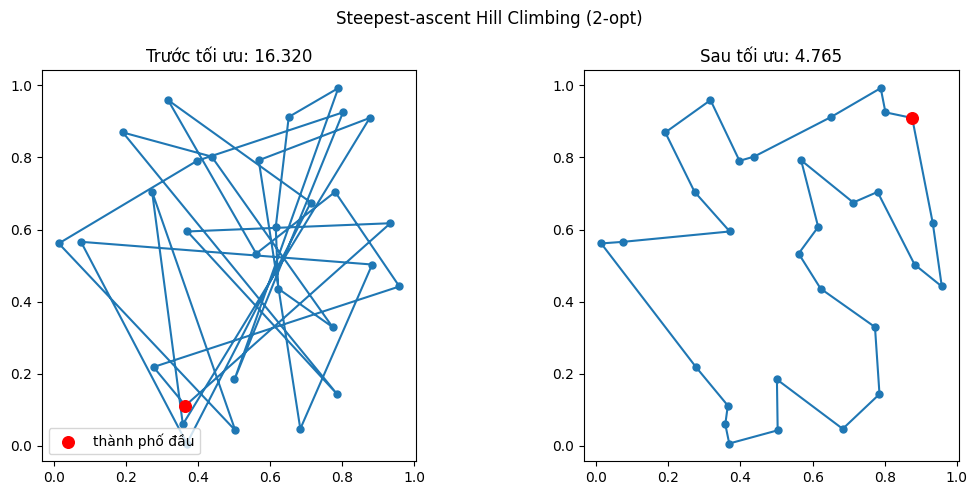

In [21]:
def steepest_ascent(tsp, tour=None):
    """Steepest-ascent hill climbing: ở mỗi bước xét TOÀN BỘ lân cận 2-opt và chọn nước đi tốt nhất.
    Dừng khi không còn nước đi nào làm tour ngắn hơn (cực trị địa phương)."""
    n = len(tsp["dist"])
    cur = list(tour) if tour is not None else random_tour(n)
    moves = two_opt_neighbours(n)

    while True:
        best_delta, best_move = -EPS, None
        for i, j in moves:
            delta = two_opt_delta(tsp, cur, i, j)
            if delta < best_delta:
                best_delta, best_move = delta, (i, j)
        if best_move is None:
            return cur
        cur = two_opt_move(cur, *best_move)


t0 = time.time()
best = steepest_ascent(tsp30, init30)
t1 = time.time()
print(f"Steepest-ascent: {tour_length(tsp30, best):.3f} | {(t1 - t0) * 1e3:.1f} ms | hợp lệ: {is_valid_tour(best, 30)}")
show_before_after(tsp30, init30, best, "Steepest-ascent Hill Climbing (2-opt)")

### Nhận xét: Steepest-ascent Hill Climbing

* **Kết quả:** tour giảm từ 16.320 xuống **4.765** (giảm khoảng 71%) và là tour hợp lệ.
* **Dừng ở đâu:** thuật toán dừng khi không còn nước đi 2-opt nào làm tour ngắn hơn, tức là một **cực trị địa phương** (mình đã kiểm tra lại: không còn $\Delta < 0$ nào). Trong bài toán Euclid, một tour 2-opt tối ưu địa phương không có hai cạnh cắt nhau, vì hai cạnh cắt nhau luôn có thể gỡ ra để được tour ngắn hơn.
* **Tính tất định:** với cùng tour khởi đầu, thuật toán luôn cho cùng một kết quả. Nó không có cơ chế thoát khỏi cực trị địa phương.
* **Chi phí:** mỗi bước phải xét toàn bộ khoảng $n(n-1)/2$ nước đi (mỗi nước $O(1)$), và số bước tăng theo $n$. Vì vậy thời gian tăng nhanh theo $n$ (xem bảng ở phần so sánh: tăng khoảng 10 lần khi $n$ từ 50 lên 100).
* **So với các phương pháp khác trên bài này:** 4.765 kém khoảng 4% so với tour tốt nhất tìm được (4.576, của Random restarts). Đây là điểm yếu điển hình của hill climbing: kết quả phụ thuộc nhiều vào điểm xuất phát.

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

Random restarts (10 lần): 4.576 | 105.8 ms | hợp lệ: True


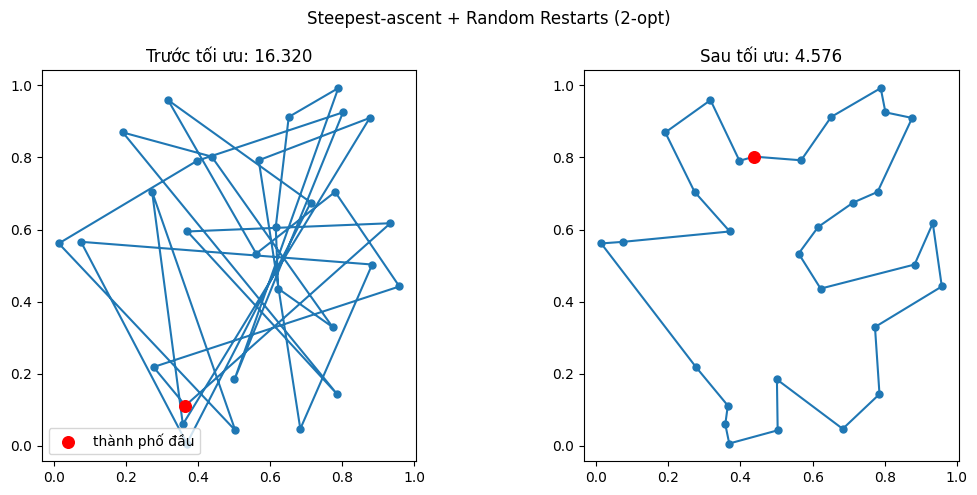

In [22]:
def random_restarts(tsp, n_restarts=10, local_search=steepest_ascent):
    """Chạy local_search từ n_restarts tour ngẫu nhiên khác nhau và giữ kết quả tốt nhất."""
    n = len(tsp["dist"])
    best, best_len = None, float("inf")
    for _ in range(n_restarts):
        cand = local_search(tsp, random_tour(n))
        cand_len = tour_length(tsp, cand)
        if cand_len < best_len:
            best, best_len = cand, cand_len
    return best


t0 = time.time()
best = random_restarts(tsp30, n_restarts=10)
t1 = time.time()
print(f"Random restarts (10 lần): {tour_length(tsp30, best):.3f} | {(t1 - t0) * 1e3:.1f} ms | hợp lệ: {is_valid_tour(best, 30)}")
show_before_after(tsp30, init30, best, "Steepest-ascent + Random Restarts (2-opt)")

### Nhận xét: Steepest-ascent với Random Restarts

* **Kết quả:** **4.576**, tốt nhất trong 5 thuật toán ở bài 30 thành phố này, cải thiện khoảng 4% so với một lần chạy steepest-ascent đơn lẻ (4.765).
* **Vì sao tốt hơn:** mỗi lần khởi động lại là một lần "thử vận may" ở một vùng khác của không gian trạng thái. Lấy tốt nhất trong 10 cực trị địa phương gần như chắc chắn không tệ hơn một cực trị đơn lẻ.
* **Cái giá:** chi phí tăng khoảng **8 – 11 lần** (đúng bằng số lần restart). Điều này thể hiện rõ trong bảng so sánh: ở $n = 100$ thuật toán này mất vài giây, chậm nhất trong các phương pháp.
* **Lưu ý khi đọc hình:** `random_restarts` tự sinh các tour khởi đầu ngẫu nhiên và **không dùng** `init30`. Hình "Trước tối ưu" chỉ để tham chiếu cùng bài toán, không phải điểm xuất phát thật của thuật toán này.
* Thuật toán này không "thông minh" hơn steepest-ascent mà chỉ dùng thêm tài nguyên tính toán. Nếu muốn so sánh công bằng theo thời gian, nên xem xét cả chất lượng trên mỗi đơn vị thời gian chứ không chỉ chất lượng cuối cùng.

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

Stochastic HC: 4.740 | 16.6 ms | hợp lệ: True


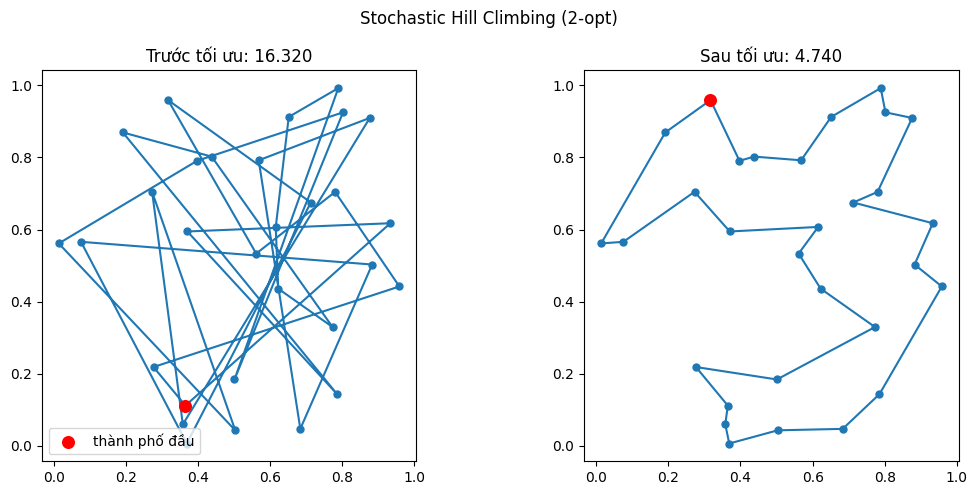

In [23]:
def stochastic_hill_climbing(tsp, tour=None):
    """Stochastic hill climbing: liệt kê mọi nước đi cải thiện rồi chọn NGẪU NHIÊN một nước trong số đó."""
    n = len(tsp["dist"])
    cur = list(tour) if tour is not None else random_tour(n)
    moves = two_opt_neighbours(n)

    while True:
        uphill = [(i, j) for i, j in moves if two_opt_delta(tsp, cur, i, j) < -EPS]
        if not uphill:
            return cur
        cur = two_opt_move(cur, *random.choice(uphill))


t0 = time.time()
best = stochastic_hill_climbing(tsp30, init30)
t1 = time.time()
print(f"Stochastic HC: {tour_length(tsp30, best):.3f} | {(t1 - t0) * 1e3:.1f} ms | hợp lệ: {is_valid_tour(best, 30)}")
show_before_after(tsp30, init30, best, "Stochastic Hill Climbing (2-opt)")

### Nhận xét: Stochastic Hill Climbing

* **Kết quả:** **4.740**, gần như ngang steepest-ascent (4.765) trên bài này. Tuy nhiên đây chỉ là một lần chạy; sự chênh lệch nhỏ như vậy chủ yếu là do may rủi.
* **Cơ chế:** ở mỗi bước, thuật toán vẫn phải duyệt **toàn bộ** lân cận để liệt kê các nước đi cải thiện rồi mới chọn ngẫu nhiên một nước. Do đó chi phí mỗi bước bằng steepest-ascent.
* **Vì sao thường kém hơn steepest-ascent:** một nước đi cải thiện được chọn ngẫu nhiên thường chỉ cải thiện rất ít, nên cần nhiều bước hơn để đến cực trị địa phương, và không có lý do để cực trị đó tốt hơn. Kết hợp hai điều này nên thuật toán vừa chậm hơn vừa thường cho tour dài hơn khi $n$ lớn (xem phần so sánh).
* **Ưu điểm:** tính ngẫu nhiên giúp mỗi lần chạy cho kết quả khác nhau, thích hợp để kết hợp với restart khi muốn đa dạng hoá.

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

First-choice HC: 5.184 | 15.9 ms | hợp lệ: True


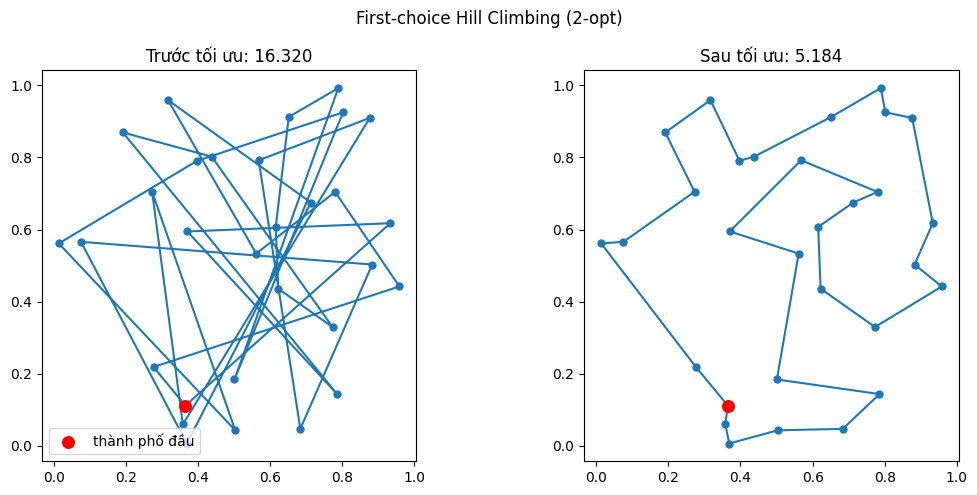

In [24]:
def first_choice_hill_climbing(tsp, tour=None, max_failures=None):
    """First-choice hill climbing: sinh MỘT lân cận 2-opt ngẫu nhiên mỗi lần và nhận ngay nếu tốt hơn.
    Dừng sau max_failures lần thử liên tiếp không cải thiện (mặc định 2*n*(n-1), gấp ~4 lần kích thước lân cận)."""
    n = len(tsp["dist"])
    cur = list(tour) if tour is not None else random_tour(n)
    if max_failures is None:
        max_failures = 2 * n * (n - 1)

    failures = 0
    while failures < max_failures:
        i, j = sorted(random.sample(range(n), 2))
        if i == 0 and j == n - 1:
            continue
        if two_opt_delta(tsp, cur, i, j) < -EPS:
            cur = two_opt_move(cur, i, j)
            failures = 0
        else:
            failures += 1
    return cur


t0 = time.time()
best = first_choice_hill_climbing(tsp30, init30)
t1 = time.time()
print(f"First-choice HC: {tour_length(tsp30, best):.3f} | {(t1 - t0) * 1e3:.1f} ms | hợp lệ: {is_valid_tour(best, 30)}")
show_before_after(tsp30, init30, best, "First-choice Hill Climbing (2-opt)")

### Nhận xét: First-choice Hill Climbing

* **Kết quả:** **5.184**, kém nhất trong 5 thuật toán ở bài này (dài hơn khoảng 13% so với 4.576). Đổi lại, nó rất nhanh (~16 ms), vì không phải quét toàn bộ lân cận ở mỗi bước.
* **Điều kiện dừng:** thuật toán dừng sau `max_failures = 2n(n-1)` lần thử liên tiếp không cải thiện, khoảng 4 lần kích thước lân cận. Vì lấy mẫu có hoàn lại, xác suất bỏ sót một nước cải thiện duy nhất sau chừng đó lần thử là khoảng $e^{-4} \approx 1.8\%$. Mình đã kiểm tra thực nghiệm trên 30 bài toán 50 thành phố: cả 30 kết quả đều là cực trị địa phương thật sự. Như vậy kết quả kém hơn **không** do dừng sớm, mà do thuật toán nhận ngay nước đi cải thiện đầu tiên bất kể mức cải thiện lớn hay nhỏ.
* **Đánh đổi:** First-choice cho tốc độ cao nhất khi $n$ lớn (ở $n = 100$ nhanh hơn steepest-ascent khoảng 3 – 4 lần) nhưng chất lượng tour thường thấp hơn. Nó phù hợp khi lân cận rất lớn và việc duyệt toàn bộ là quá đắt.
* Tham số `max_failures` quyết định cân bằng giữa chất lượng và thời gian: tăng lên thì chắc chắn hơn nhưng chậm hơn.

## Simulated Annealing [2 Points]

Simulated annealing: 4.585 | 111.0 ms | hợp lệ: True


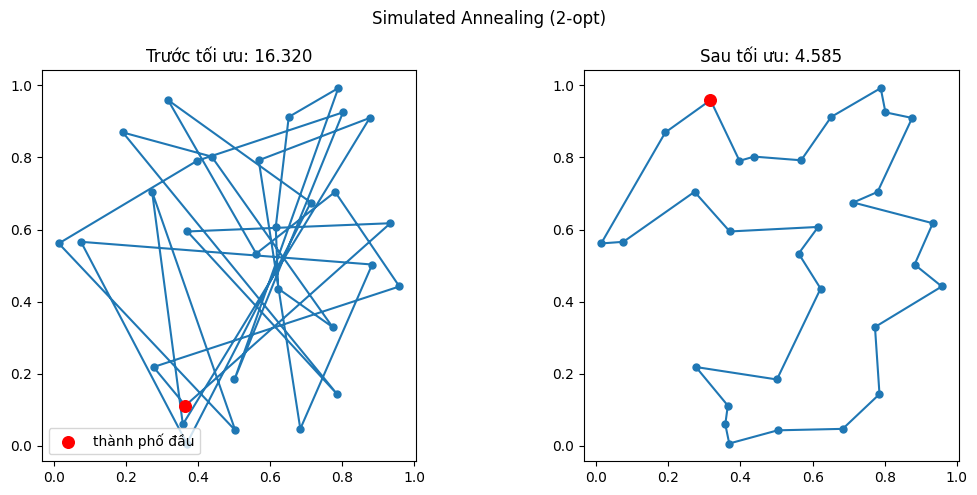

In [25]:
def simulated_annealing(tsp, tour=None, T0=0.5, T_min=1e-3, alpha=0.995, iters_per_T=None):
    """Simulated annealing với lân cận 2-opt và lịch làm nguội hình học."""
    n = len(tsp["dist"])
    cur = list(tour) if tour is not None else random_tour(n)
    if iters_per_T is None:
        iters_per_T = n

    cur_len = tour_length(tsp, cur)
    best, best_len = list(cur), cur_len
    T = T0

    while T > T_min:
        for _ in range(iters_per_T):
            i, j = sorted(random.sample(range(n), 2))
            if i == 0 and j == n - 1:
                continue
            delta = two_opt_delta(tsp, cur, i, j)
            if delta < 0 or random.random() < math.exp(-delta / T):
                cur = two_opt_move(cur, i, j)
                cur_len += delta
                if cur_len < best_len - EPS:
                    best, best_len = list(cur), cur_len
        T *= alpha
    return best


t0 = time.time()
best = simulated_annealing(tsp30, init30)
t1 = time.time()
print(f"Simulated annealing: {tour_length(tsp30, best):.3f} | {(t1 - t0) * 1e3:.1f} ms | hợp lệ: {is_valid_tour(best, 30)}")
show_before_after(tsp30, init30, best, "Simulated Annealing (2-opt)")

### Nhận xét: Simulated Annealing

* **Kết quả:** **4.585**, gần bằng Random restarts (4.576) trong khi chỉ cần một lần chạy, và tốt hơn rõ rệt so với ba biến thể hill climbing đơn lẻ (4.74 – 5.18).
* **Cơ chế thoát cực trị địa phương:** thuật toán chấp nhận nước đi làm tour **dài hơn** với xác suất $e^{-\Delta/T}$. Khi nhiệt độ $T$ cao thì gần như đi ngẫu nhiên (khám phá), khi $T$ giảm dần thì ngày càng giống hill climbing (khai thác). Thuật toán trả về tour **tốt nhất từng gặp**, không phải tour ở trạng thái cuối cùng, nên không bị mất nghiệm tốt do nhiễu ở giai đoạn nóng.
* **Lịch làm nguội:** $T_0 = 0.5$ (cùng bậc với độ dài một cạnh điển hình trong hình vuông 1×1, nên giai đoạn đầu chấp nhận hầu hết các nước đi), nhân với $\alpha = 0.995$ mỗi lần cho đến $T_{min} = 10^{-3}$, với $n$ lần thử mỗi mức nhiệt, tổng khoảng $1240 \cdot n$ lần thử. Tổng số lần thử chỉ tăng **tuyến tính theo $n$**, vì vậy thời gian tăng chậm hơn nhiều so với steepest-ascent.
* **Hạn chế:** các tham số được giữ cố định cho mọi $n$ và chưa được tinh chỉnh. Với $n$ lớn, lịch làm nguội này có thể là chưa đủ chậm; với $n$ nhỏ thì lại dư thừa (xem phần so sánh: ở $n = 10$ SA chậm hơn steepest-ascent hàng trăm lần mà không tốt hơn đáng kể).

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [26]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.3342628479003906 milliseconds


Chiều dài tour trung bình / tốt nhất và thời gian chạy trung bình (ms):


,n,algorithm,mean_length,best_length,mean_time_ms
0,10,Steepest-ascent,3.00,2.60,0.23
1,10,Random restarts (10),2.98,2.53,2.09
2,10,Stochastic HC,3.04,2.60,0.47
3,10,First-choice HC,2.98,2.53,2.02
4,10,Simulated annealing,2.98,2.53,35.38
5,20,Steepest-ascent,3.81,3.24,2.67
6,20,Random restarts (10),3.78,3.24,19.46
7,20,Stochastic HC,3.83,3.38,4.88
8,20,First-choice HC,3.82,3.24,4.34
9,20,Simulated annealing,3.80,3.26,84.66


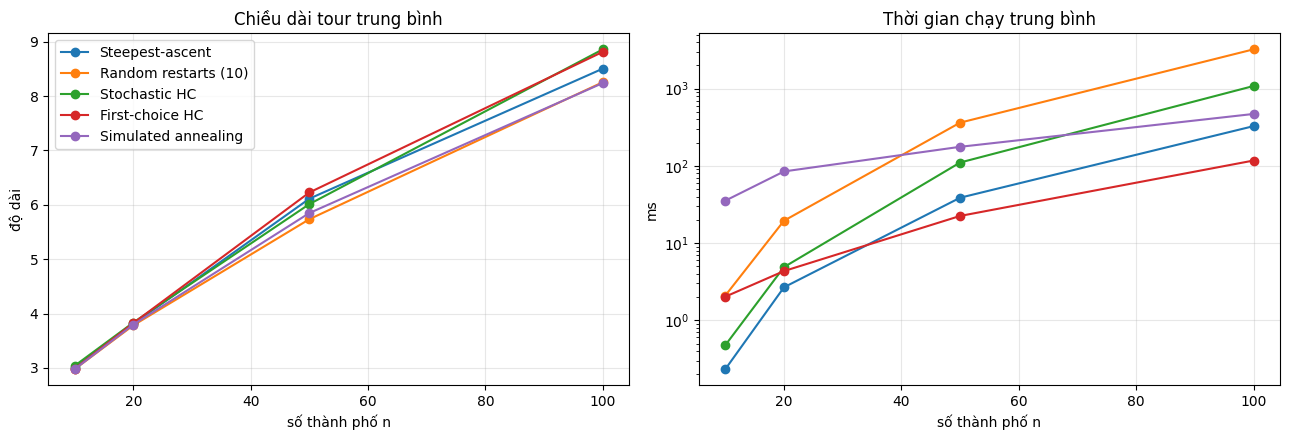

In [27]:
algorithms = {
    "Steepest-ascent":     lambda tsp, t0_: steepest_ascent(tsp, t0_),
    "Random restarts (10)": lambda tsp, t0_: random_restarts(tsp, n_restarts=10),
    "Stochastic HC":       lambda tsp, t0_: stochastic_hill_climbing(tsp, t0_),
    "First-choice HC":     lambda tsp, t0_: first_choice_hill_climbing(tsp, t0_),
    "Simulated annealing": lambda tsp, t0_: simulated_annealing(tsp, t0_),
}

sizes = [10, 20, 50, 100]
n_runs = 5            # số lần chạy độc lập cho mỗi (thuật toán, kích thước) để lấy trung bình
records = []

for n in sizes:
    for run in range(n_runs):
        random.seed(1000 * n + run)
        np.random.seed(1000 * n + run)
        tsp_n = random_tsp(n)
        start = random_tour(n)                # cùng tour khởi đầu cho mọi thuật toán
        for name, algo in algorithms.items():
            t0 = time.time()
            result = algo(tsp_n, start)
            elapsed = (time.time() - t0) * 1e3
            assert is_valid_tour(result, n), f"{name} trả về tour không hợp lệ"
            records.append({"n": n, "run": run, "algorithm": name,
                            "start_length": tour_length(tsp_n, start),
                            "length": tour_length(tsp_n, result), "time_ms": elapsed})

results = pd.DataFrame(records)
summary = results.groupby(["n", "algorithm"], sort=False).agg(
    mean_length=("length", "mean"), best_length=("length", "min"),
    mean_time_ms=("time_ms", "mean")).reset_index()

print("Chiều dài tour trung bình / tốt nhất và thời gian chạy trung bình (ms):")
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name in algorithms:
    s = summary[summary["algorithm"] == name]
    axes[0].plot(s["n"], s["mean_length"], "-o", label=name)
    axes[1].plot(s["n"], s["mean_time_ms"], "-o", label=name)
axes[0].set_title("Chiều dài tour trung bình"); axes[0].set_xlabel("số thành phố n"); axes[0].set_ylabel("độ dài")
axes[1].set_title("Thời gian chạy trung bình"); axes[1].set_xlabel("số thành phố n"); axes[1].set_ylabel("ms")
axes[1].set_yscale("log"); axes[0].legend(); axes[0].grid(alpha=.3); axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()

### Nhận xét: so sánh hiệu năng

**Cách đọc kết quả.** Bảng trên báo cáo độ dài trung bình theo từng $n$, nhưng mỗi $n$ chỉ có 5 bài toán ngẫu nhiên khác nhau, nên độ dài tuyệt đối dao động theo bài toán (độ lệch chuẩn giữa các bài khoảng 0.2 – 0.4). Để so sánh công bằng hơn, mình tính thêm **độ lệch theo cặp**: với mỗi bài toán, đo mỗi thuật toán dài hơn tour tốt nhất mà 5 thuật toán tìm được bao nhiêu phần trăm, rồi lấy trung bình trên 5 bài. (Đây là so với tour tốt nhất *tìm được*, không phải tối ưu thật sự vì ta không biết nghiệm tối ưu.)

| Thuật toán | n = 10 | n = 20 | n = 50 | n = 100 |
|---|---|---|---|---|
| Steepest-ascent | 0.9% | 0.6% | 6.7% | 4.6% |
| Random restarts (10) | **0.0%** | **0.0%** | **0.0%** | 1.6% |
| Stochastic HC | 2.1% | 1.4% | 4.8% | 8.9% |
| First-choice HC | 0.3% | 1.1% | 8.5% | 8.4% |
| Simulated annealing | **0.0%** | 0.4% | 2.0% | **1.3%** |

**1. Chất lượng.**
* Random restarts và Simulated annealing cho tour tốt nhất ở mọi kích thước. Random restarts thắng rõ ở $n \le 50$; ở $n = 100$ SA nhỉnh hơn một chút (1.3% so với 1.6%), chênh lệch này nhỏ so với dao động giữa các bài toán nên không nên kết luận là SA tốt hơn.
* Ba hill climbing "đơn lẻ" (steepest, stochastic, first-choice) kém hơn và **khoảng cách tăng theo $n$**: ở $n = 10$ chỉ lệch 0.3 – 2%, nhưng ở $n = 100$ lệch 4.6 – 8.9%. Điều này hợp lý vì số cực trị địa phương tăng nhanh theo $n$, nên xác suất rơi vào một cực trị tệ cũng tăng.
* Giữa ba thuật toán này, steepest-ascent thường nhỉnh hơn hai biến thể ngẫu nhiên khi $n$ lớn, nhưng với 5 bài toán mỗi cỡ thì thứ hạng giữa chúng chưa thật chắc chắn.

**2. Thời gian chạy.**
* Steepest-ascent tăng rất nhanh theo $n$ (mỗi bước quét $O(n^2)$ nước đi và số bước cũng tăng theo $n$): từ khoảng 0.3 ms ở $n = 10$ lên hàng trăm ms ở $n = 100$.
* Random restarts luôn chậm hơn steepest-ascent khoảng 8 – 11 lần, và là thuật toán chậm nhất ở $n = 100$ (vài giây).
* First-choice là thuật toán hill climbing nhanh nhất ở $n$ lớn nhờ không quét toàn bộ lân cận. Stochastic HC chậm hơn steepest-ascent vì tốn cùng chi phí quét mỗi bước nhưng cần nhiều bước hơn.
* Simulated annealing có chi phí gần như tuyến tính theo $n$ nên có lợi thế khi $n$ tăng, nhưng có chi phí nền cao: ở $n = 10$ nó chậm nhất (hàng chục ms) dù không tốt hơn đáng kể.

**3. Chất lượng trên mỗi đơn vị thời gian (khả năng mở rộng).**
* Với bài nhỏ ($n \le 20$), mọi thuật toán đều cho kết quả gần nhau, nên dùng steepest-ascent hoặc first-choice là đủ và rẻ nhất.
* Với $n$ trung bình (≈ 50), Random restarts cho tour tốt nhất nhưng tốn chi phí gấp nhiều lần; SA là lựa chọn rẻ hơn với chất lượng kém hơn một chút.
* Với $n$ lớn (≈ 100), **Simulated annealing** là lựa chọn hợp lý nhất: chất lượng ngang Random restarts nhưng thời gian chỉ bằng khoảng một phần mười, và gần bằng một lần chạy steepest-ascent.

**4. Hạn chế của thí nghiệm.**
* Chỉ 5 lần chạy cho mỗi $n$ nên các chênh lệch dưới khoảng 1 – 2% (ví dụ RR so với SA ở $n = 100$) chưa đủ để kết luận. Nên tăng `n_runs` (ví dụ 20 – 30) nếu cần kết luận chắc hơn.
* Cùng tour khởi đầu được dùng cho mọi thuật toán, **ngoại trừ Random restarts** vốn tự sinh các tour khởi đầu riêng.
* Tham số của SA (`T0`, `alpha`, `iters_per_T`) được giữ cố định và chưa tinh chỉnh; kết quả của SA có thể cải thiện thêm nếu điều chỉnh theo $n$.
* Thời gian đo bằng `time.time()` trong Python thuần và phụ thuộc vào máy, nên nên đọc theo **tỉ lệ giữa các thuật toán** thay vì giá trị tuyệt đối. Bảng cũng chỉ hiển thị 2 chữ số thập phân do `pd.set_option('display.precision', 2)` ở đầu notebook, dù code đã làm tròn `round(3)`.

## Bonus: Genetic Algorithm [+1 Point]

Cài đặt một Genetic Algorithm (GA) chuẩn cho TSP, dùng lại các hàm đã có (`tour_length`, `two_opt_move`, `random_tour`) để so sánh công bằng với các thuật toán phía trên.

| Thành phần | Lựa chọn |
|---|---|
| **Biểu diễn** | mỗi cá thể là một hoán vị các thành phố (một tour) |
| **Hàm thích nghi** | độ dài tour (càng nhỏ càng tốt) |
| **Quần thể ban đầu** | 100 tour ngẫu nhiên (cộng với tour khởi đầu `init30` ở vị trí đầu tiên) |
| **Chọn lọc** | tournament, chọn ngẫu nhiên $k = 3$ cá thể rồi lấy cá thể tốt nhất |
| **Lai ghép** | *order crossover* (OX): giữ một đoạn của cha, điền phần còn lại theo thứ tự xuất hiện ở mẹ, nên con luôn là hoán vị hợp lệ |
| **Đột biến** | với xác suất 0.2, đảo ngược một đoạn ngẫu nhiên (một phép 2-opt ngẫu nhiên) |
| **Elitism** | giữ nguyên 2 cá thể tốt nhất sang thế hệ sau, nên tour tốt nhất không bao giờ tệ đi |
| **Số thế hệ** | 300 (tổng cộng khoảng 30 000 lần tính độ dài tour) |

Genetic algorithm: 4.648 | 561.4 ms | hợp lệ: True


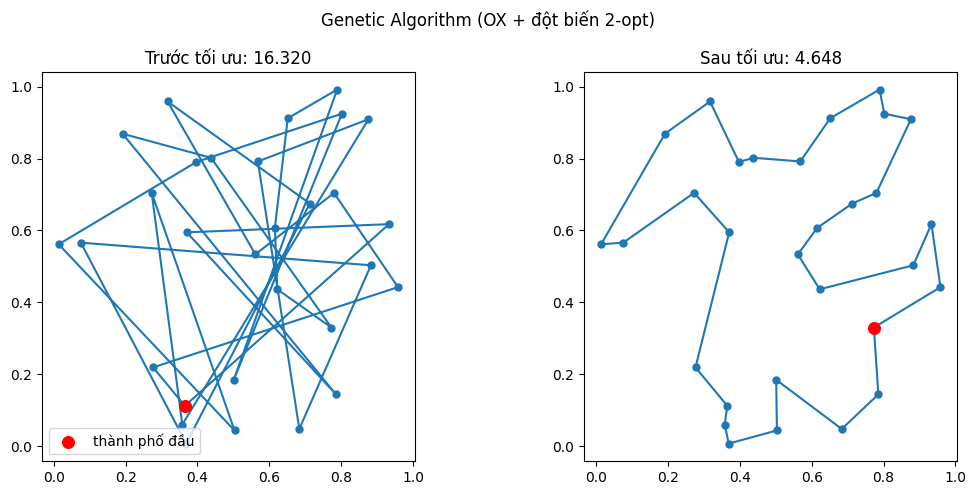

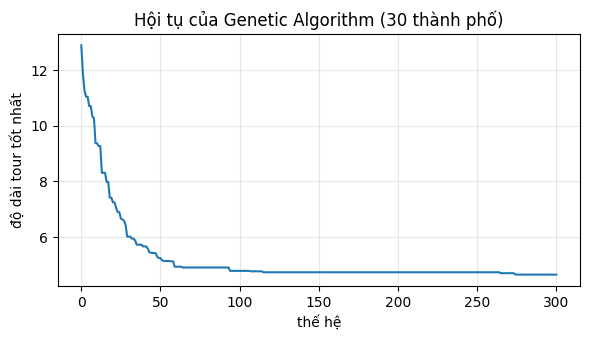

Tour tốt nhất: thế hệ 0 = 12.892 | thế hệ 50 = 5.244 | thế hệ 150 = 4.733 | cuối = 4.648


In [28]:
def order_crossover(p1, p2):
    """Order crossover (OX): giữ nguyên một đoạn của cha p1, phần còn lại điền theo thứ tự xuất hiện trong mẹ p2.
    Kết quả luôn là hoán vị hợp lệ."""
    n = len(p1)
    a, b = sorted(random.sample(range(n), 2))
    child = [None] * n
    child[a:b + 1] = p1[a:b + 1]
    used = set(child[a:b + 1])
    fill = [c for c in p2 if c not in used]
    k = 0
    for idx in list(range(0, a)) + list(range(b + 1, n)):
        child[idx] = fill[k]
        k += 1
    return child


def mutate(tour, p_mut):
    """Đột biến: với xác suất p_mut, đảo ngược một đoạn ngẫu nhiên (chính là một phép 2-opt ngẫu nhiên)."""
    if random.random() < p_mut:
        i, j = sorted(random.sample(range(len(tour)), 2))
        return two_opt_move(tour, i, j)
    return tour


def genetic_algorithm(tsp, tour=None, pop_size=100, generations=300, p_mut=0.2,
                      tournament_k=3, n_elite=2, return_history=False):
    """Genetic algorithm cho TSP: chọn lọc giải đấu, lai ghép OX, đột biến đảo đoạn, giữ lại n_elite cá thể tốt nhất.
    Nếu có `tour`, nó được đưa vào quần thể ban đầu (các cá thể còn lại là ngẫu nhiên)."""
    n = len(tsp["dist"])
    pop = [random_tour(n) for _ in range(pop_size)]
    if tour is not None:
        pop[0] = list(tour)
    fit = [tour_length(tsp, t) for t in pop]
    history = []

    def select():
        cand = random.sample(range(pop_size), tournament_k)
        return pop[min(cand, key=lambda k: fit[k])]

    for _ in range(generations):
        order = sorted(range(pop_size), key=lambda k: fit[k])
        history.append(fit[order[0]])                      # tour tốt nhất của thế hệ hiện tại
        new_pop = [list(pop[k]) for k in order[:n_elite]]  # elitism
        while len(new_pop) < pop_size:
            child = order_crossover(select(), select())
            new_pop.append(mutate(child, p_mut))
        pop = new_pop
        fit = [tour_length(tsp, t) for t in pop]

    best_k = min(range(pop_size), key=lambda k: fit[k])
    history.append(fit[best_k])
    best = pop[best_k]
    return (best, history) if return_history else best


t0 = time.time()
best, history = genetic_algorithm(tsp30, init30, return_history=True)
t1 = time.time()
print(f"Genetic algorithm: {tour_length(tsp30, best):.3f} | {(t1 - t0) * 1e3:.1f} ms | hợp lệ: {is_valid_tour(best, 30)}")
show_before_after(tsp30, init30, best, "Genetic Algorithm (OX + đột biến 2-opt)")

plt.figure(figsize=(6, 3.5))
plt.plot(history)
plt.xlabel("thế hệ"); plt.ylabel("độ dài tour tốt nhất")
plt.title("Hội tụ của Genetic Algorithm (30 thành phố)")
plt.grid(alpha=.3)
plt.tight_layout()
plt.show()
print(f"Tour tốt nhất: thế hệ 0 = {history[0]:.3f} | thế hệ 50 = {history[50]:.3f} | thế hệ 150 = {history[150]:.3f} | cuối = {history[-1]:.3f}")

### Nhận xét: Genetic Algorithm (bài 30 thành phố)

* **Kết quả:** **4.648**. Tốt hơn steepest-ascent (4.765), stochastic HC (4.740) và first-choice HC (5.184), nhưng vẫn kém Random restarts (4.576) và Simulated annealing (4.585). Mất khoảng **561 ms** (chậm hơn cả steepest-ascent lẫn stochastic HC, xấp xỉ Random restarts và SA).
* **Hội tụ:** tour tốt nhất của quần thể giảm rất nhanh lúc đầu (từ **12.892** ở thế hệ 0 xuống **5.244** ở thế hệ 50), sau đó cải thiện chậm dần (**4.733** ở thế hệ 150, **4.648** ở cuối). Đường cong chỉ đi xuống hoặc đi ngang vì có elitism.
* **Lưu ý:** đây là **một lần chạy** và GA có tính ngẫu nhiên khá lớn. Trong phần so sánh bên dưới, GA ngang bằng nhóm dẫn đầu ở $n = 10$ (0.00%), nhưng tụt lại rõ rệt khi $n$ tăng (3.44% ở $n = 20$, 12.59% ở $n = 50$, và **62.65% ở $n = 100$** — tệ nhất trong 6 thuật toán). Nguyên nhân chính là GA dùng ngân sách cố định 300 thế hệ × 100 cá thể cho mọi $n$, nên ở $n$ lớn nó chưa đủ thời gian hội tụ, còn ở $n$ nhỏ thì dư thừa. Vì vậy kết luận nên dựa vào bảng so sánh chứ không chỉ một lần chạy.

In [29]:
ga_records = []
for n in sizes:
    for run in range(n_runs):
        random.seed(1000 * n + run)           # cùng seed với phần so sánh phía trên -> cùng bài toán, cùng tour khởi đầu
        np.random.seed(1000 * n + run)
        tsp_n = random_tsp(n)
        start = random_tour(n)
        random.seed(50000 + 1000 * n + run)   # seed riêng cho GA để kết quả lặp lại được
        t0 = time.time()
        result = genetic_algorithm(tsp_n, start)
        elapsed = (time.time() - t0) * 1e3
        assert is_valid_tour(result, n), "GA trả về tour không hợp lệ"
        ga_records.append({"n": n, "run": run, "algorithm": "Genetic algorithm",
                           "start_length": tour_length(tsp_n, start),
                           "length": tour_length(tsp_n, result), "time_ms": elapsed})

results_all = pd.concat([results, pd.DataFrame(ga_records)], ignore_index=True)
summary_all = results_all.groupby(["n", "algorithm"], sort=False).agg(
    mean_length=("length", "mean"), best_length=("length", "min"),
    mean_time_ms=("time_ms", "mean")).reset_index()
print("Genetic algorithm so với 5 thuật toán còn lại:")
print(summary_all[summary_all["algorithm"] == "Genetic algorithm"].round(3).to_string(index=False))

# độ lệch theo cặp: mỗi thuật toán dài hơn tour tốt nhất (trong cả 6 thuật toán) bao nhiêu %, trung bình trên các bài toán
results_all["gap_%"] = results_all.groupby(["n", "run"])["length"].transform(lambda x: (x / x.min() - 1) * 100)
print("\nĐộ lệch trung bình so với tour tốt nhất trong 6 thuật toán (%):")
print(results_all.groupby(["algorithm", "n"], sort=False)["gap_%"].mean().unstack("n").round(2).to_string())

Genetic algorithm so với 5 thuật toán còn lại:
  n         algorithm  mean_length  best_length  mean_time_ms
 10 Genetic algorithm         2.98         2.53        372.44
 20 Genetic algorithm         3.91         3.24        461.78
 50 Genetic algorithm         6.45         6.11        643.13
100 Genetic algorithm        13.22        12.95        917.14

Độ lệch trung bình so với tour tốt nhất trong 6 thuật toán (%):
n                      10    20     50     100
algorithm                                     
Steepest-ascent       0.89  0.62   6.69   4.61
Random restarts (10)  0.00  0.00   0.00   1.56
Stochastic HC         2.10  1.44   4.82   8.91
First-choice HC       0.31  1.05   8.51   8.43
Simulated annealing   0.00  0.37   2.00   1.31
Genetic algorithm     0.00  3.44  12.59  62.65


### Nhận xét: GA so với các thuật toán còn lại

* **Bài nhỏ ($n \le 20$):** GA cho kết quả tốt (bằng tour tốt nhất tìm được ở $n = 10$, chỉ lệch 3.4% ở $n = 20$), nhưng rất tốn kém cho bài nhỏ (khoảng 372 – 462 ms trong khi steepest-ascent chỉ cần vài ms).
* **Bài lớn:** chất lượng GA **giảm rất nhanh khi $n$ tăng**: lệch 12.6% ở $n = 50$ và 62.7% ở $n = 100$ so với tour tốt nhất. Ở $n = 100$ GA tệ hơn hẳn cả ba hill climbing đơn giản.
* **Giải thích:** GA dùng ngân sách **cố định** (100 cá thể × 300 thế hệ, khoảng 30 000 lần đánh giá) trong khi không gian tìm kiếm tăng giai thừa theo $n$. Ngoài ra GA thuần túy không có bước tinh chỉnh cục bộ: lai ghép OX giữ được thứ tự nhưng không giữ tốt các cạnh ngắn, nên khó "chỉnh" tour về gần cực trị địa phương như 2-opt.
* **Kiểm tra giả thuyết về ngân sách:** trên một bài 100 thành phố, tăng số thế hệ từ 300 lên 1500 làm tour giảm từ 12.75 xuống 8.65, tức là phần lớn khoảng cách do GA chưa kịp hội tụ. Tuy nhiên tăng tiếp lên 4000 thế hệ không cải thiện thêm (vẫn 8.65): quần thể đã **hội tụ sớm**, mất đa dạng. Đây chỉ là một bài toán nên chỉ mang tính gợi ý.
* **Hướng cải thiện** (chưa thử trong notebook này): tăng số thế hệ và kích thước quần thể theo $n$, tăng tỉ lệ đột biến hoặc chèn cá thể ngẫu nhiên để giữ đa dạng, hoặc kết hợp GA với local search (*memetic algorithm*: áp dụng vài bước 2-opt cho mỗi cá thể con).
* **Kết luận:** với tham số mặc định này, GA không cạnh tranh được với local search có toán tử 2-opt ở $n \ge 50$. Kết luận chung ở phần *Compare Performance* không đổi: Random restarts và Simulated annealing vẫn là hai lựa chọn tốt nhất.